In [14]:
import os
import sys
import warnings

import joblib
import pandas as pd
import numpy as np

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_models.matrix_profile_detector import MatrixProfileDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'MatrixProfile'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True
M_SECONDS = 0.3 # Window size in seconds for the matrix profile algorithm

In [15]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [16]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


In [17]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series:   0%|          | 0/95 [00:00<?, ?it/s]

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 1639.69it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


In [18]:
# =========================================================================
# Base vars for future calculations
# =========================================================================

results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

total_samples = len(results_temp_base)                                  
total_trials  = len(df_filtered[['sub', 'repID']].drop_duplicates())
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100


if total_samples != X_movement.shape[0]:
    raise ValueError(
        f"⚠️ ERROR: Metadata ({total_samples}) does not match the matrix "
        f"({X_movement.shape[0]})!"
    )

print(
    f"✅ Perfect synchronization! Matrix rows: {X_movement.shape[0]} | "
    f"Metadata rows: {total_samples}"
)
print(f"Total samples in the matrix: {total_samples}")
print(f"Total trials: {total_trials}")
print(f"Total known outliers: {total_known_outliers}")
print(f"Known outlier rate: {percentagem_conhecida:.2f}%")

✅ Perfect synchronization! Matrix rows: 95 | Metadata rows: 95
Total samples in the matrix: 95
Total trials: 95
Total known outliers: 18
Known outlier rate: 5.26%


## Matrix Profile

### Grid Search

In [19]:
print("--- Starting LOSO Baseline: Matrix Profile ---")

m = max(3, round(M_SECONDS * Configs.FS))

param_grid_mp = [
    {'m': m, 'contamination': c}
    for c in Configs.CONTAMINATION_GRID
]

warnings.filterwarnings("ignore", category=RuntimeWarning) # Avoid mindless devided by 0 warnings when normalize is True
warnings.filterwarnings("ignore", category=UserWarning) # Avoid warnings about self-joins when using Matrix Profile

loso_results = run_loso_evaluation(
    detector_class=MatrixProfileDetector, 
    param_grid=param_grid_mp,
    data_matrix=X_movement, 
    metadata_df=results_temp_base,
    known_outliers_df=outliers_csv,
    metric_type='euclidean',
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

--- Starting LOSO Baseline: Matrix Profile ---
LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Avaliação Estatística (TRIAL-LEVEL) - Bootstraping

In [20]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [21]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for MatrixProfile - ShapeBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 20
Rejection Rate: 21.05%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  3
Total False Positives (Global): 17
Total False Negatives (Global): 2
Total True Negatives (Global):  73
------------------------------
Blind Precision: 15.00 [0.00–35.71]
Blind Recall:    60.00 [0.00–100.00]
Blind F1-Score:  24.00
Blind F2-Score:  37.50 [0.00–64.15]
Blind MCC:       0.23 [-0.07–0.48]
Blind AUPRC:  28.96 [4.89–80.95]
Blind AUROC:   81.56

Total Tuning Time (19 Subjects): 333.9107s
Total Inference Time (19 Subjects): 6.4064s

Overall Best Parameters (Most frequent across folds):
   {'contamination': 0.09, 'm': 18}
Occurrences: 10


### Train Model

In [22]:
best_params = loso_results['Best_Params']
best_m = best_params['m']
best_contamination = best_params['contamination']

In [23]:
final_mp_model = MatrixProfileDetector(metric_type='euclidean', m=best_m, contamination=best_contamination)
labels = final_mp_model.fit_predict(X_movement)
joblib.dump(final_mp_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

outlier_indices = np.where(labels == -1)[0]
outliers_details = results_temp_base.iloc[outlier_indices]
n_outliers = len(outlier_indices)

n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Garbage Percentage (sub + repID + movID): {(n_outliers / len(results_temp_base)) * 100:.2f}%")
print(f"Detected Garbage Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 9
Unique Outlier Trials Detected: 9
Detected Garbage Percentage (sub + repID + movID): 9.47%
Detected Garbage Percentage (sub + repID): 9.47%


In [24]:
# Reconstruct metadata to cross-check with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

real_outliers_info = metadata_df.iloc[outlier_indices]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Outlier Details:")
print(real_outliers_info)

Outlier Details:
    sub  repID  movID movLabel
6     2      2      9     Move
14    3      5      9     Move
21    5      2      9     Move
23    5      4      9     Move
50   11      1      9     Move
55   12      1      9     Move
79   16      5      9     Move
82   17      3      9     Move
84   17      5      9     Move


In [25]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 3
False Positives (Identified, not in CSV): 6
False Negatives (In CSV, not identified): 2
True Negatives (Normal, stayed normal): 84
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
1    4      1
2    7      1

Precision (False Positives): 3/9 (33.33%)
Recall (True Positive Rate): 3/5 (60.00%)
F1-Score: 42.86%
F2-Score: 51.72%


### Plot Things

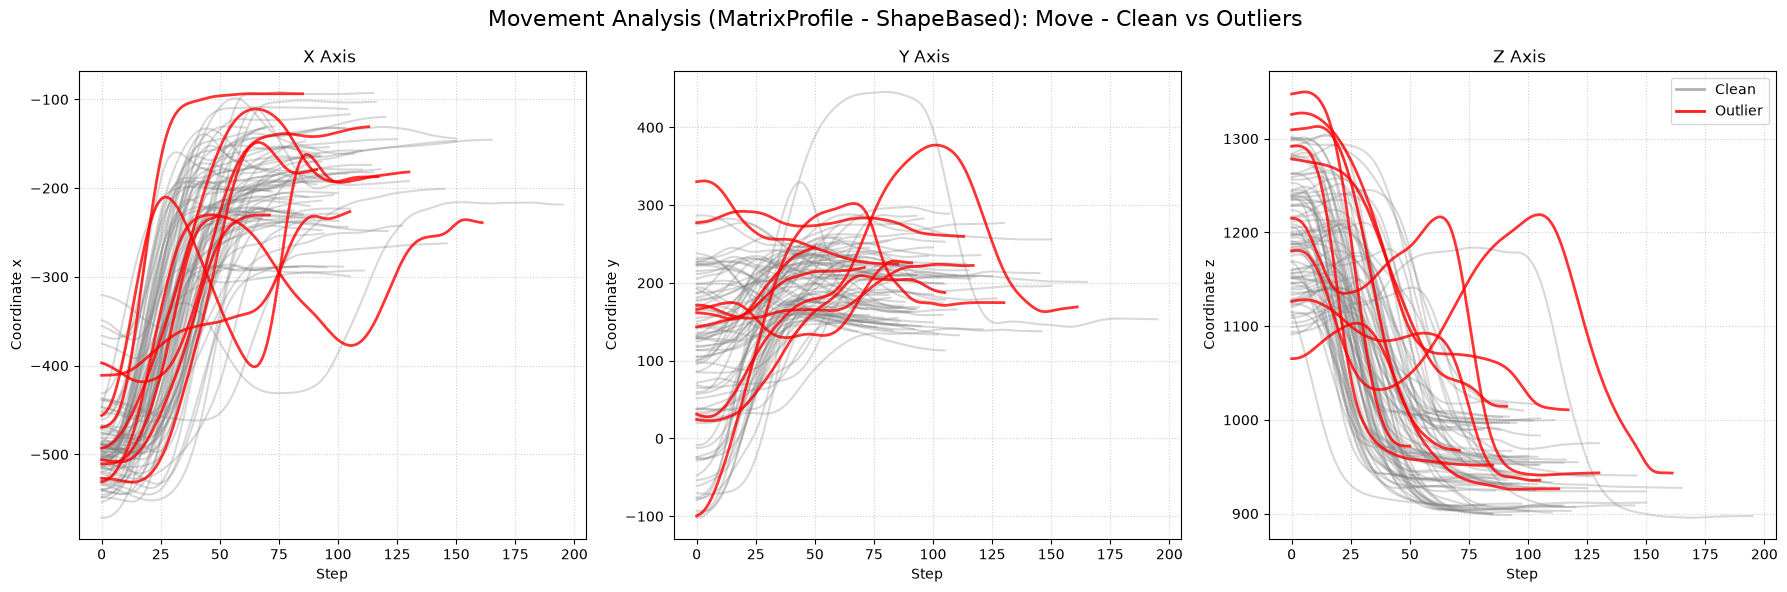

In [26]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)